# SubCellSeg quickstart

This notebook segments an example image with the pretrained SubCellSeg model and
shows the result. It then shows how to do the same with your own image.

To run it you need the developer installation from
[docs/INSTALL.md](../docs/INSTALL.md), with two extras for reading the example
image from the web and for plotting:

```
uv pip install --python .venv --torch-backend auto -e ".[zarr,notebook]"
```

Then activate the environment and start Jupyter from it with `jupyter lab`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from subcellseg import SubCellSeg, io

## 1. Load an image

The example is a public 3D image of human induced pluripotent stem cells from
the Allen Institute for Cell Science, in which alpha-actinin-1 is tagged with
a fluorescent protein. The file holds several channels; SubCellSeg needs the one
with the tagged structure.

In [2]:
url = "https://animatedcell-test-data.s3.us-west-2.amazonaws.com/variance/10932.zarr"

image = io.open_image(url)
print("channels:", image.channel_names)

volume = io.read_volume(image, channel="Labeled Structure")
print("shape (Z, Y, X):", volume.shape)

channels: ['Membrane', 'Labeled Structure', 'DNA', 'Bright field', 'SEG_STRUCT', 'SEG_Memb', 'SEG_DNA', 'Con_Memb', 'Con_DNA']
shape (Z, Y, X): (65, 624, 924)


## 2. Segment it

`SubCellSeg()` loads the pretrained model (downloaded the first time).
`predict_proba` gives every voxel a score between 0 and 1 for how likely it
belongs to the structure. The mask is every voxel that scores above 0.5.

In [3]:
model = SubCellSeg()
print("running on:", model.device)

probability = model.predict_proba(volume)
mask = probability > 0.5
print(f"{mask.mean():.1%} of the volume is segmented as structure")

running on: cuda
1.3% of the volume is segmented as structure


## 3. Look at the result

One z-slice from the middle of the stack.

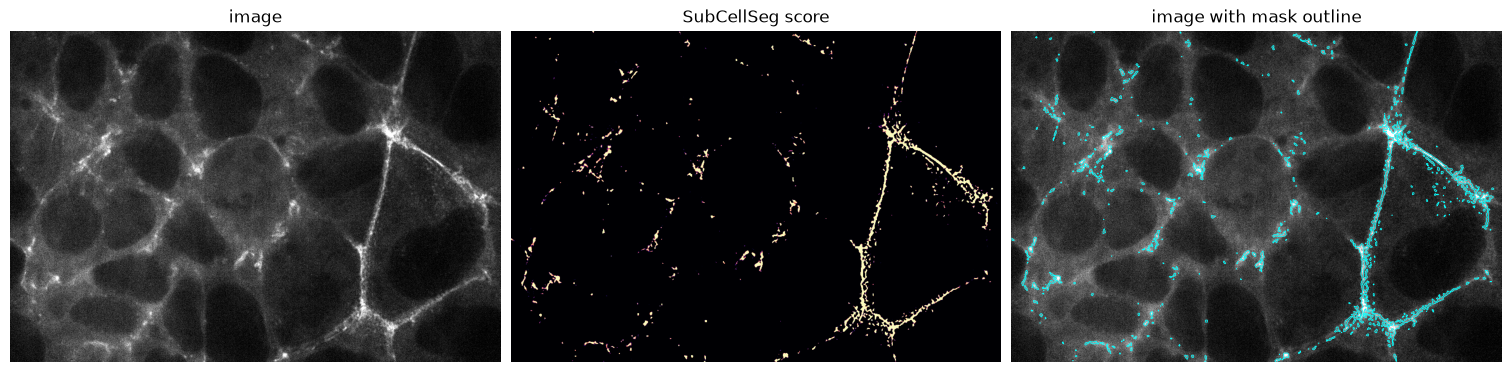

In [4]:
z = volume.shape[0] // 2
low, high = np.percentile(volume[z], [1, 99.9])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
axes[0].imshow(volume[z], cmap="gray", vmin=low, vmax=high)
axes[0].set_title("image")
axes[1].imshow(probability[z], cmap="magma", vmin=0, vmax=1)
axes[1].set_title("SubCellSeg score")
axes[2].imshow(volume[z], cmap="gray", vmin=low, vmax=high)
axes[2].contour(mask[z], levels=[0.5], colors="cyan", linewidths=0.5)
axes[2].set_title("image with mask outline")
for ax in axes:
    ax.axis("off")

A closer look at one region.

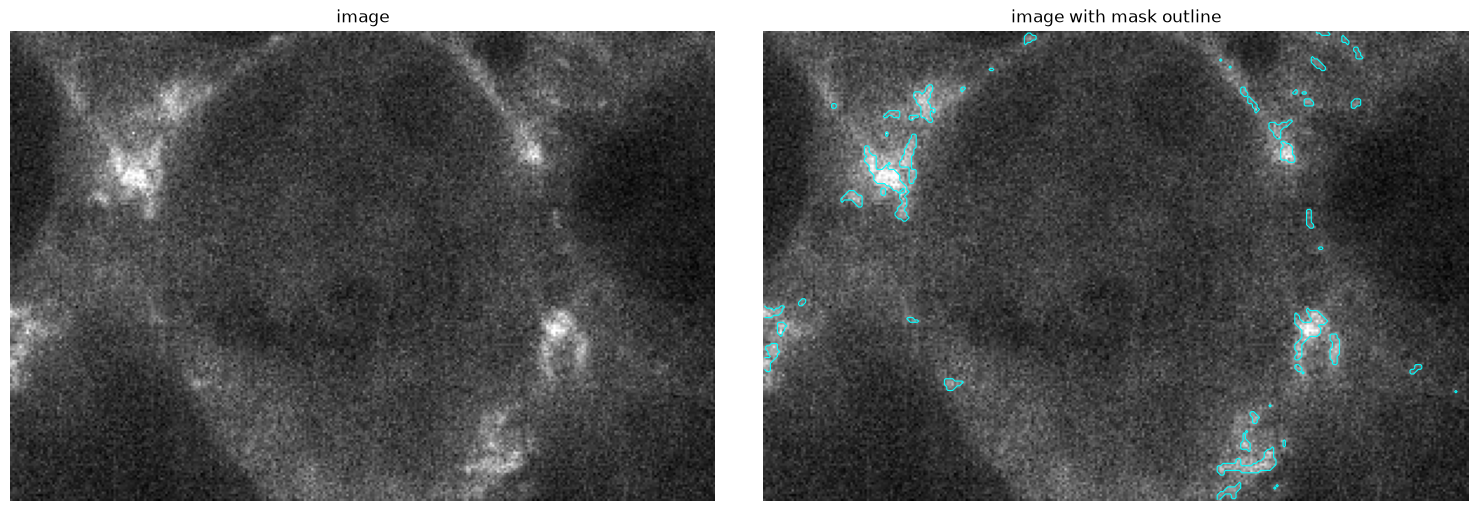

In [5]:
ys, xs = slice(200, 400), slice(300, 600)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
axes[0].imshow(volume[z, ys, xs], cmap="gray", vmin=low, vmax=high)
axes[0].set_title("image")
axes[1].imshow(volume[z, ys, xs], cmap="gray", vmin=low, vmax=high)
axes[1].contour(mask[z, ys, xs], levels=[0.5], colors="cyan", linewidths=0.8)
axes[1].set_title("image with mask outline")
for ax in axes:
    ax.axis("off")

## 4. Save the mask

This writes a TIFF you can open in Fiji or napari. It keeps the voxel size of
the original image.

In [6]:
io.write_volume(
    "example_seg.tif",
    mask.astype(np.uint8) * 255,
    voxel_size=io.pixel_sizes(image),
)

## Your own image

Replace the loading step with your file. Any 3D array with axes (Z, Y, X) works:

```python
import tifffile

volume = tifffile.imread("my_image.tif")   # must be (Z, Y, X)
mask = model.segment(volume)               # uint8: 255 inside the structure
tifffile.imwrite("my_image_seg.tif", mask)
```

For a whole folder, or for files with several channels or timepoints,
`subcellseg.predict` does the reading and saving for you:

```python
import subcellseg

subcellseg.predict("my_images", "results", channel=1)
```

## Fine-tuning

Fine-tuning on your own images and masks is one call. It is explained step by
step in [docs/TRAINING.md](../docs/TRAINING.md).

```python
import subcellseg

best = subcellseg.train("my_data/train.csv", output_dir="my_model", init="pretrained")
subcellseg.predict("my_images", "results", checkpoint=best)
```